# Illullip Sermia Data Download Notebook #   
This notebook downloads the following datasets for Illullip Sermia:
1. MEaSUREs-0781 Terminus Positions for Illullip Sermia
2. MEaSUREs-0766 Velocity Data for Illullip Sermia
3. IceBridge BedMachine Greenland, Version 7

Illullip Sermia is __Glacier #34__ in MEaSUREs-0766 AND MEaSUREs-0781 and __Glacier #33__ in Felikson Flowline Dataset

In [1]:
#import libraries and packages
import earthaccess
import geopandas as gpd
from pathlib import Path 
import os
import xarray as xr
import dask
import panel 
import pandas as pd
import matplotlib.pyplot as plt
import nisardev as nisar
import grimpfunc as grimp
from pathlib import Path
from dask.diagnostics import ProgressBar
ProgressBar().register()
dask.config.set(num_workers = 2) # avoid problems with too many open connections at NSIDC
panel.extension()
earthaccess.login()

In [2]:
# set data paths
data_dir = Path.home() / "Desktop" / "GrIS_Calving" / "data"
data_path = data_dir /"MEaSUREs_0781/JakobshavnIsbrae"

termini = gpd.read_file(data_path / "glacier_termini_v01.0.shp")
points = gpd.read_file(data_path / "glacier_points_v01.0.shp")
boxes = gpd.read_file(data_path / "glacier_boxes_v01.0.shp")

In [3]:
# select glacier: Illullip Sermia = 34 
glacier_ID = 34
glacier_name = "IllullipSermia"

# check selected glacier
print(points.loc[points["Glacier_ID"] == glacier_ID, ["Official_N", "Alternativ", "Glacier_ID"]])

# subset the termini data to grab specifically Store Gletsjer (Glacier ID 9) -- change name and Glacier_ID for different glaciers 
glacier_termini = termini[termini["Glacier_ID"] == glacier_ID].copy()

         Official_N         Alternativ  Glacier_ID
30  Illullip Sermia  Igdlugdlip Sermia          34


In [4]:
#set/create output directory
outdir = data_dir / "MeASUREs_0781" / glacier_name / "processed"
outdir.mkdir(exist_ok=True, parents=True) #create directory if it doesn't exist

terminus_output_file = outdir / f"{glacier_name}Terminus.shp"

if not terminus_output_file.exists():
    glacier_termini.to_file(terminus_output_file)
    print(f"Saved: {terminus_output_file}")
else:
    print(f"File already exists, skipping: {terminus_output_file}")

File already exists, skipping: /Users/ssuhinin/Desktop/GrIS_Calving/data/MeASUREs_0781/IllullipSermia/processed/IllullipSermiaTerminus.shp


In [5]:
env = dict(GDAL_HTTP_COOKIEFILE = os.path.expanduser('~/.grimp_download_cookiejar.txt'),
            GDAL_HTTP_COOKIEJAR = os.path.expanduser('~/.grimp_download_cookiejar.txt'))
os.environ.update(env)

In [8]:
import sys
import requests
import grimpfunc
from grimpfunc import cmr as grimp_cmr

CMR_URL = "https://cmr.earthdata.nasa.gov/search/granules.json"
PAGE_SIZE = 2000

def get_urls_fixed(short_name, version, time_start, time_end, bounding_box=None, polygon=None, filename_filter=None,verbose=False):
    params = {
        "provider": "NSIDC_CPRD",
        "sort_key[]": ["start_date", "producer_granule_id"],
        "page_size": PAGE_SIZE,
        "short_name": short_name,
        "version": version,
        "temporal[]": f"{time_start},{time_end}",
    }
    if bounding_box:
        params["bounding_box[]"] = bounding_box
    if polygon:
        params["polygon[]"] = polygon
    if filename_filter:
        params["producer_granule_id[]"] = filename_filter
        params["options[producer_granule_id][pattern]"] = "true"

    urls, headers = [], {}
    while True:
        r = requests.get(CMR_URL, params=params, headers=headers, timeout=60)
        if verbose:
            print(r.status_code, r.url)
        r.raise_for_status()
        results = r.json()
        urls += grimp_cmr.cmr_filter_urls(results)
        token = r.headers.get("CMR-Search-After")
        # Page not full (or no more pages) so done
        if len(results["feed"]["entry"]) < PAGE_SIZE or not token:
            break
        headers["CMR-Search-After"] = token
    return [str(x) for x in urls]

# Swap it in everywhere the library might look it up
grimp_cmr.get_urls = get_urls_fixed
grimpfunc.get_urls = get_urls_fixed
cu = sys.modules.get("grimpfunc.cmrUrls")
if cu is not None and hasattr(cu, "grimp"):
    cu.grimp.get_urls = get_urls_fixed

In [9]:
myUrls = grimp.cmrUrls(mode='subsetter')
display(myUrls.initialSearch(product='NSIDC-0766'))
myCogs = myUrls.getCogs(replace='vv', removeTiff=True)

BokehModel(combine_events=True, render_bundle={'docs_json': {'01c0759a-0b8e-42d3-a29a-8ca4b0b6ffc8': {'version…

In [10]:
# load glacier terminus data from earlier 
terminus = gpd.read_file(terminus_output_file)
terminus = terminus.to_crs("EPSG:3413")

# define the bounding box for the velocity data download based on the terminus shapefile
minx, miny, maxx, maxy = terminus.total_bounds

# add 15 km margin/bugger around glacier termini
margin = 15000

bbox = {"minx": minx - margin, "maxx": maxx + margin, "miny": miny - margin, "maxy": maxy + margin}
print("bbox:", bbox)

bbox: {'minx': np.float64(-343748.01679992676), 'maxx': np.float64(-311102.1781001091), 'miny': np.float64(-1685900.1314001083), 'maxy': np.float64(-1650640.2042000294)}


In [11]:
# create a velocity series object with the COGs searched for above
velocity_series = nisar.nisarVelSeries()
velocity_series.readSeriesFromTiff(myCogs, url=True, readSpeed=False)

# subset to glacier bounding box
velocity_series.subSetVel(bbox)

RasterioIOError: '/vsicurl/?list_dir=no&url=https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/MEASURES/NSIDC-0766/2/2015/01/01/GL_vel_mosaic_s1cycle_01Jan15_12Jan15_velocity_vx_v02.1.tif' not recognized as being in a supported file format.

In [ ]:
# create a velocity series object with the COGs searched for above
velocity_series = nisar.nisarVelSeries()
velocity_series.readSeriesFromTiff(myCogs, url=True, readSpeed=False)

# subset to glacier bounding box
velocity_series.subSetVel(bbox)

In [ ]:
# set/create output directory
velocity_outdir = data_dir / "MEaSUREs_0766" / glacier_name / "processed"
velocity_outdir.mkdir(exist_ok=True, parents=True)

# save velocity data if not already saved
velocity_output_file = velocity_outdir / f"{glacier_name}VelocitySeries.nc"

if not velocity_output_file.exists():
    velocity_series.toNetCDF(str(velocity_output_file))
    print(f"Saved: {velocity_output_file}")
else:
    print(f"File already exists, skipping: {velocity_output_file}")

In [ ]:
# load Greenland-wide BedMachine v7 dataset
bedmachine_path = data_dir / "BedMachine" / "BedMachineGreenland-v7.nc"
bedmachine = xr.open_dataset(bedmachine_path)

# inspect the dataset
bedmachine

<xarray.Dataset> Size: 4GB
Dimensions:    (x: 10218, y: 18346)
Coordinates:
  * x          (x) int32 41kB -652925 -652775 -652625 ... 879325 879475 879625
  * y          (y) int32 73kB -632675 -632825 -632975 ... -3384275 -3384425
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 187MB ...
    surface    (y, x) float32 750MB ...
    thickness  (y, x) float32 750MB ...
    bed        (y, x) float32 750MB ...
    errbed     (y, x) float32 750MB ...
    source     (y, x) int8 187MB ...
    dataid     (y, x) int8 187MB ...
    geoid      (y, x) float32 750MB ...
    rgi        (y, x) int8 187MB ...
Attributes: (12/19)
    Conventions:                 CF-1.7, ACDD-1.3
    title:                       BedMachine Greenland v7
    creator_name:                Mathieu Morlighem
    creator_email:               mathieu.morlighem@dartmouth.edu
    creator_institution:         Department of Earth and Planetary Sciences, ...
    product_version:             v7.0
    ...                          ...
    references:                  Morlighem M. et al., (2017), BedMachine v3: ...
    keywords:                    EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SH...
    summary:                     This dataset contains a bed topography/bathy...
    time_coverage_start:         1970-01-01
    time_coverage_end:           2019-10-01
    nominal_year:                2008

In [ ]:
# define the BedMachine bounding box for the bedmachine data based on the terminus/velocity data
bedmachine_is = bedmachine.sel(x=slice(bbox["minx"], bbox["maxx"]), y=slice(bbox["maxy"], bbox["miny"]))

# inspect subset
bedmachine_is

<xarray.Dataset> Size: 1MB
Dimensions:    (x: 217, y: 235)
Coordinates:
  * x          (x) int32 868B -343625 -343475 -343325 ... -311375 -311225
  * y          (y) int32 940B -1650725 -1650875 -1651025 ... -1685675 -1685825
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 51kB ...
    surface    (y, x) float32 204kB ...
    thickness  (y, x) float32 204kB ...
    bed        (y, x) float32 204kB ...
    errbed     (y, x) float32 204kB ...
    source     (y, x) int8 51kB ...
    dataid     (y, x) int8 51kB ...
    geoid      (y, x) float32 204kB ...
    rgi        (y, x) int8 51kB ...
Attributes: (12/19)
    Conventions:                 CF-1.7, ACDD-1.3
    title:                       BedMachine Greenland v7
    creator_name:                Mathieu Morlighem
    creator_email:               mathieu.morlighem@dartmouth.edu
    creator_institution:         Department of Earth and Planetary Sciences, ...
    product_version:             v7.0
    ...                          ...
    references:                  Morlighem M. et al., (2017), BedMachine v3: ...
    keywords:                    EARTH SCIENCE > CRYOSPHERE > GLACIERS/ICE SH...
    summary:                     This dataset contains a bed topography/bathy...
    time_coverage_start:         1970-01-01
    time_coverage_end:           2019-10-01
    nominal_year:                2008

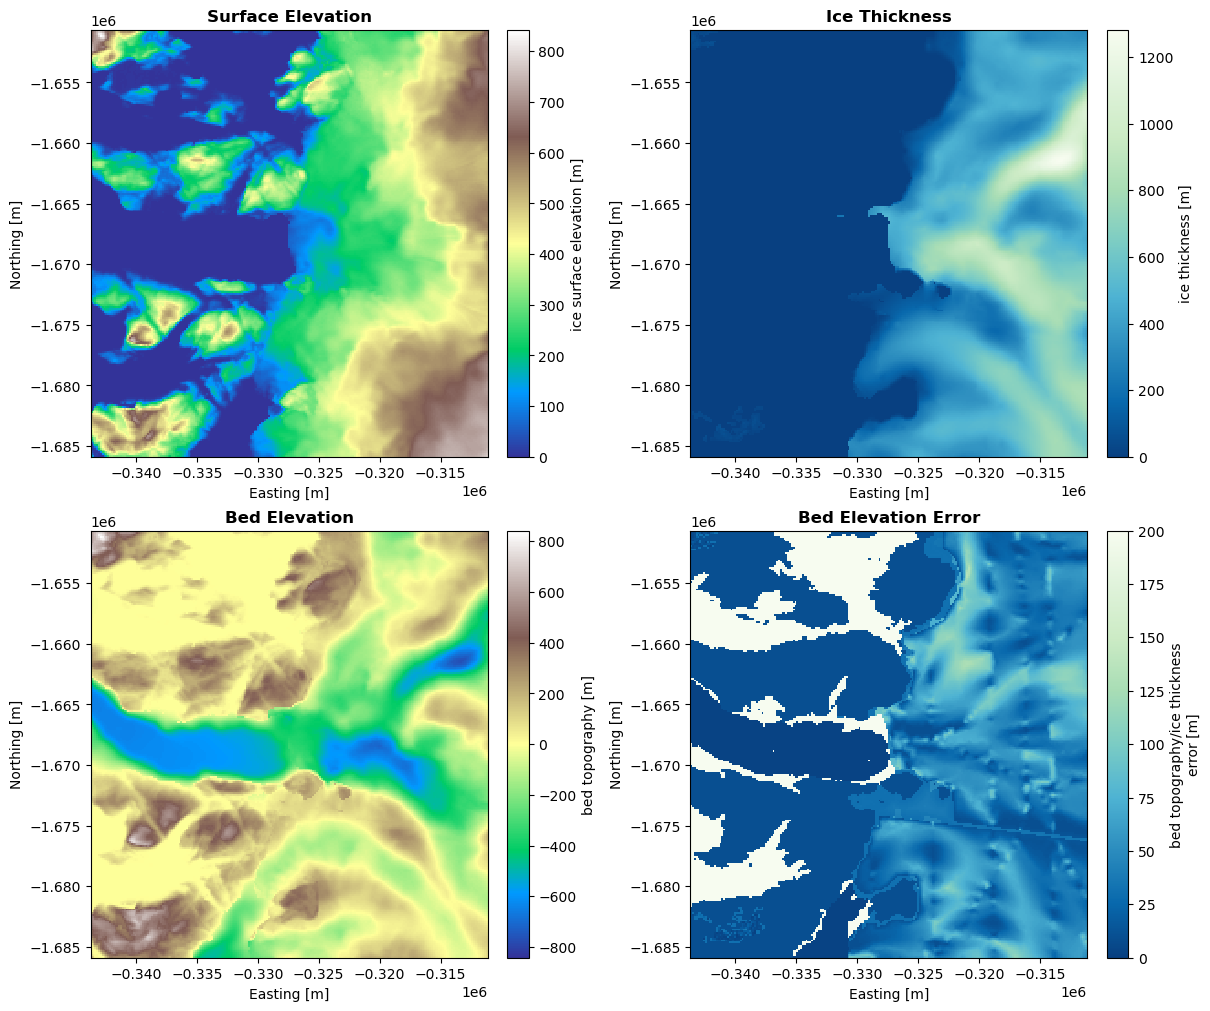

In [ ]:
# plot verification of data
fig, ax = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

bedmachine_is["surface"].plot(ax=ax[0, 0], cmap="terrain")
ax[0, 0].set_title("Surface Elevation", fontweight = "bold")

bedmachine_is["thickness"].plot( ax=ax[0, 1], cmap="GnBu_r")
ax[0, 1].set_title("Ice Thickness", fontweight = "bold")

bedmachine_is["bed"].plot(ax=ax[1, 0], cmap="terrain")
ax[1, 0].set_title("Bed Elevation", fontweight = "bold")

bedmachine_is["errbed"].plot(ax=ax[1, 1], cmap="GnBu_r")
ax[1, 1].set_title("Bed Elevation Error", fontweight = "bold")


for a in ax.flat:
    a.set_xlabel("Easting [m]")
    a.set_ylabel("Northing [m]")
    a.ticklabel_format(axis="both", style="sci", scilimits=(6,6)) 


plt.show()

In [ ]:
# set/create output directory
output_dir = data_dir / "BedMachine" / glacier_name / "processed"
output_file = os.path.join(output_dir, 'KangilliupSermiaBedMachineV7.nc')

os.makedirs(output_dir, exist_ok=True)

bedmachine_is.to_netcdf(output_file)